## 1. Титульный лист
# Инженерия признаков: прогноз покупки в e-commerce
**Лабораторная работа №4. Машинное обучение и искусственный интеллект**  
**Выполнил:** Федорушкин Станислав · **Группа:** ПКТб-23-1  
**Дата выполнения:** 29.10.2026 · **Учебный год:** 2026/2027  
**Репозиторий:** https://github.com/Ogn1k/ml-course-fedorushkin  
**Файл:** `module-4-features/notebook.ipynb`

## 2. Введение
Задача — оценить вероятность завершения сессии покупкой (Revenue). Такая оценка помогает
приоритизировать поддержку, тестировать предложения и планировать маркетинговые кампании.
Инженерия признаков переводит исходные измерения в более содержательные характеристики:
например, общее время сессии и соотношение отказов и выходов.

Цели: создать не менее пяти признаков; сравнить RF, XGBoost, LightGBM и CatBoost;
подобрать параметры с Optuna и объяснить результат с SHAP.
Основная метрика — ROC-AUC, дополнительно PR-AUC, F1, Precision и Recall.
Accuracy сама по себе малоинформативна: большинство сессий не заканчивается покупкой.
Порог 0.5 фиксирован заранее; его бизнес-оптимизацию нужно выполнять на validation, не на test.

## 3. Теоретическая часть
**Feature Engineering.** Признак описывает объект числом или категорией. Его можно получить
из нескольких исходных полей. Сумма страниц характеризует глубину просмотра.
Отношения позволяют сопоставлять короткие и длинные сессии. Польза нового признака
проверяется сравнением на одинаковых разбиениях, а не предполагается заранее.

**Категории.** Label Encoding присваивает категории целое число. Для номинальных
категорий это может создать ложный порядок. One-Hot выделяет отдельную колонку каждой
категории; неизвестные категории при прогнозе обрабатываются через handle_unknown.
Здесь технические коды тоже считаются категориями; все модели получают одинаковое кодирование.

**Время.** Месяц позволяет учитывать сезонность. Weekend уже содержит признак выходного.
Синус и косинус месяца отражают цикличность года. Полной даты и порядка сессий нет,
поэтому лаги по строкам не имеют смысла и здесь не создаются.

**Поведение.** TotalPages суммирует посещённые страницы. TotalDuration суммирует время.
Среднее время на страницу характеризует интенсивность просмотра. Отношения требуют
защиты от деления на ноль. Производные признаки не должны использовать Revenue.

**Дисбаланс.** Модель может получать высокую Accuracy, предсказывая только отсутствие покупки.
Веса классов увеличивают штраф за ошибки на редком классе. SMOTE создаёт синтетические
объекты, но применим только внутри обучающего фолда. В этой работе используются веса и
стратификация, а PR-AUC дополняет ROC-AUC.

**SHAP.** Значения Шепли распределяют отклонение прогноза от базового уровня между признаками.
Summary показывает распределение вкладов. Bar усредняет их абсолютную величину.
Waterfall объясняет одну сессию. Dependence показывает связь значения признака с вкладом.
Для RF TreeExplainer объясняет вероятность, а для бустингов — raw margin (log-odds). Единицы проверяются ниже.
Коррелирующие признаки могут делить важность; объяснение модели не доказывает причинность.

Bagging: $\hat p(x)=\frac1B\sum_{b=1}^B p_b(x)$.
Boosting: $F_M(x)=F_0(x)+\sum_{m=1}^M\eta f_m(x)$, $p(x)=\sigma(F_M(x))$.

| Модель | Принцип | Особенность |
|---|---|---|
| Random Forest | Bagging деревьев | Снижение дисперсии усреднением |
| XGBoost | Градиентный бустинг | Регуляризация, выборки строк и колонок |
| LightGBM | Гистограммный бустинг | Быстрое построение деревьев по листьям |
| CatBoost | Градиентный бустинг | Поддержка категорий; здесь общий One-Hot для сравнения |

**Нестандартные данные из теории.** TF-IDF взвешивает слова по частоте в документе и
редкости в корпусе: $tfidf(t,d)=tf(t,d)\log(N/df(t))$. Haversine вычисляет расстояние
по широте и долготе на сфере. DBSCAN объединяет плотные группы и помечает шум как −1.
Лаг — прошлое значение; rolling — статистика прошлых значений (для прогноза сначала shift).
В данном наборе нет текстов, координат и временной последовательности: их не выдумываем.

## 4. Описание данных
Источник: [UCI, Sakar и Kastro, 2018](https://doi.org/10.24432/C5F88Q), CC BY 4.0.
12 330 сессий, 17 признаков и Revenue; 10 числовых и 7 категориальных признаков.
Administrative, Informational, ProductRelated — число страниц; поля Duration — время в секундах.
BounceRates, ExitRates — отказы и выходы; PageValues — аналитическая ценность страниц;
SpecialDay — близость особого дня; Month — месяц; Weekend — выходной;
OperatingSystems, Browser, Region, TrafficType, VisitorType — категории.

Ограничение: агрегаты описывают сессию. Для раннего онлайн-прогноза необходимо проверить
момент доступности каждого поля, особенно PageValues. Ниже также обучается модель без
PageValues и AvgPageValue. Это проверка чувствительности, а не доказательство отсутствия утечки.

In [1]:
# Импортируем библиотеки и фиксируем параметры воспроизводимости.
import io, json, time, hashlib, platform, importlib.metadata, zipfile
from pathlib import Path
import requests, joblib, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, RocCurveDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna, shap
SEED = 42
BASE = Path('.')
for folder in ['data', 'models', 'examples']:
    (BASE / folder).mkdir(exist_ok=True)

# Скачиваем только официальный архив; при повторном запуске используем локальный CSV.
DATA_URL = 'https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip'
csv_path = BASE / 'data/online_shoppers_intention.csv'
if not csv_path.exists():
    response = requests.get(DATA_URL, timeout=90)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        csv_path.write_bytes(archive.read('online_shoppers_intention.csv'))
df = pd.read_csv(csv_path)
assert df.shape == (12330, 18)
print(df.shape)
print(df.head().to_string())
df.info()
display(df.describe(include='all').T)
display(df['Revenue'].value_counts().to_frame('count').assign(share=df['Revenue'].value_counts(normalize=True)))
# Сохраняем контрольную сумму для проверки источника данных.
provenance = dict(url=DATA_URL, doi='10.24432/C5F88Q', license='CC BY 4.0',
                  sha256=hashlib.sha256(csv_path.read_bytes()).hexdigest())
Path('data/provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')

(12330, 18)
   Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  Browser  Region  TrafficType        VisitorType  Weekend  Revenue
0               0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 1        1       1            1  Returning_Visitor    False    False
1               0                      0.0              0                     0.0               2                64.000000         0.00       0.10         0.0         0.0   Feb                 2        2       1            2  Returning_Visitor    False    False
2               0                      0.0              0                     0.0               1                 0.000000         0.20       0.20         0.0         0.0   Feb                 4        

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


,count,share
Revenue,,
False,10422,0.845255
True,1908,0.154745


243

Данные загружены из UCI; фактические размеры, типы, статистика и доли классов приведены выше. Пропуски и повторяющиеся строки проверяем до разбиения.

## 5. Подготовка данных и EDA
Сначала удаляем полностью совпадающие строки, чтобы копии не пересекли train и test.
Затем откладываем 20% test со stratify. Исследовательские графики строим только по train.
Импутация, кодирование и масштабирование обучаются внутри Pipeline на train каждого CV-фолда.

| Новый признак | Обоснование |
|---|---|
| TotalPages | Глубина просмотра |
| TotalDuration | Общее время |
| AvgPageValue | Нормировка ценности на глубину |
| BounceExitRatio | Соотношение отказов и выходов |
| IsNewVisitor | Индикатор нового посетителя |
| IsWeekend | Явный бинарный выходной |
| MonthNum | Положение в годовом цикле |
| IsHighTraffic | Условное TrafficType > 10 из задания; код не означает реальную интенсивность |
| DurationPerPage | Среднее время страницы |
| MonthSin, MonthCos | Цикличность месяца |

Пропуски: 0 Дубликаты: 125


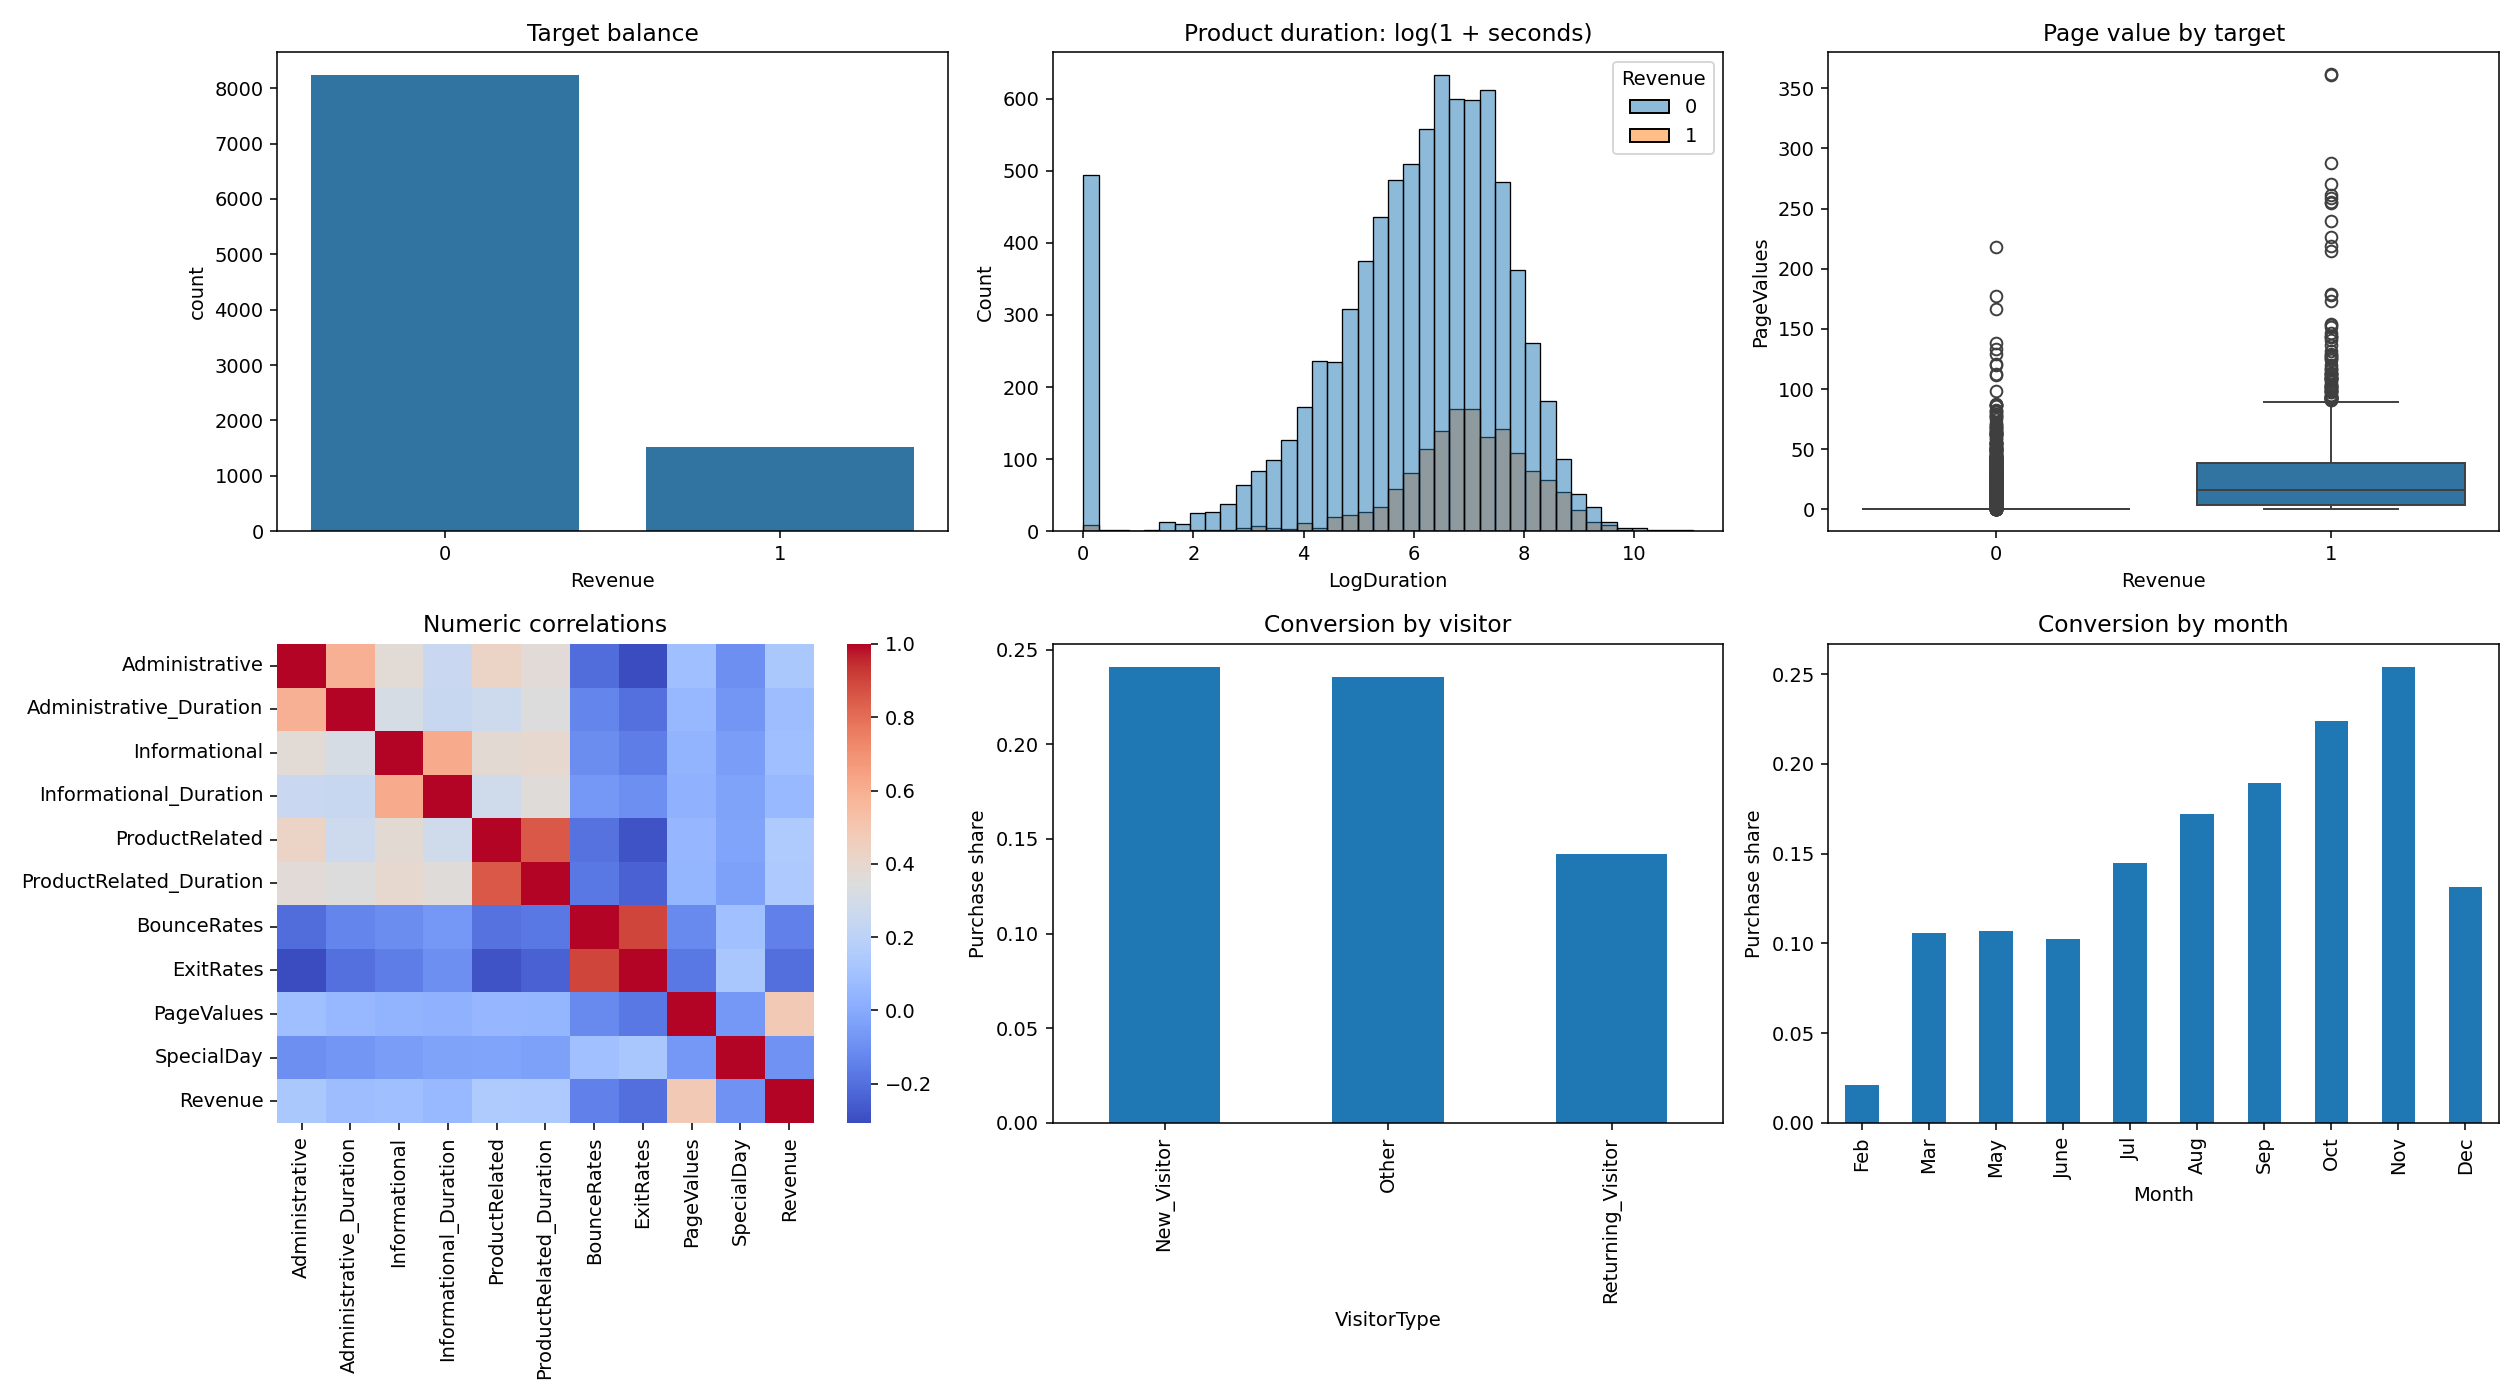

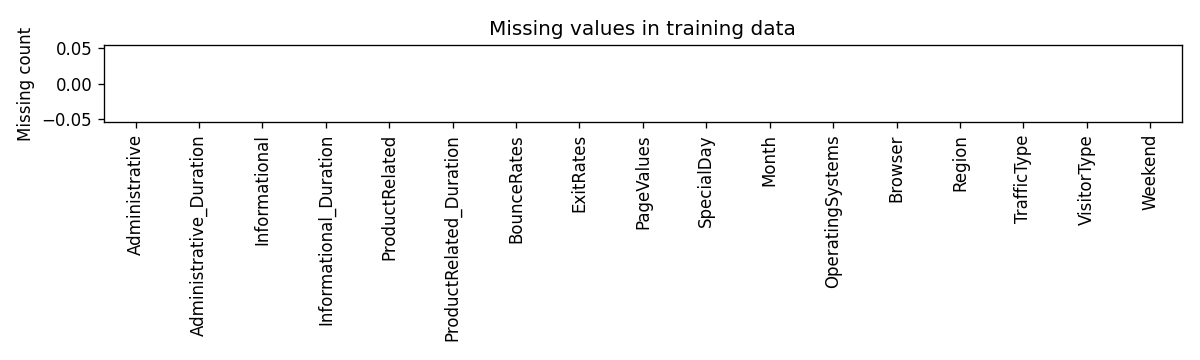

In [2]:
# Удаляем дубликаты до разделения; не используем целевую для генерации признаков.
print('Пропуски:', int(df.isna().sum().sum()), 'Дубликаты:', int(df.duplicated().sum()))
clean = df.drop_duplicates().copy()
X = clean.drop(columns='Revenue')
y = clean['Revenue'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
pd.DataFrame({'split': ['train', 'test'], 'rows': [len(y_train),len(y_test)],
              'positive_share': [y_train.mean(), y_test.mean()]}).to_csv('data/splits.csv', index=False)

# Строим шесть графиков EDA и отдельный график пропусков.
eda = X_train.assign(Revenue=y_train)
fig, axes = plt.subplots(2, 3, figsize=(18,10))
sns.countplot(data=eda, x='Revenue', ax=axes[0,0])
sns.histplot(data=eda.assign(LogDuration=np.log1p(eda['ProductRelated_Duration'])), x='LogDuration', hue='Revenue', bins=40, ax=axes[0,1])
sns.boxplot(data=eda, x='Revenue', y='PageValues', ax=axes[0,2])
sns.heatmap(eda.drop(columns=['OperatingSystems','Browser','Region','TrafficType']).select_dtypes(include='number').corr(), cmap='coolwarm', ax=axes[1,0])
eda.groupby('VisitorType')['Revenue'].mean().plot.bar(ax=axes[1,1], ylabel='Purchase share')
eda.groupby('Month')['Revenue'].mean().reindex(['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']).plot.bar(ax=axes[1,2], ylabel='Purchase share')
for ax, title in zip(axes.flat, ['Target balance','Product duration: log(1 + seconds)','Page value by target',
                              'Numeric correlations','Conversion by visitor','Conversion by month']):
    ax.set_title(title)
fig.tight_layout()
fig.savefig('examples/eda_plots.png', dpi=140)
plt.close(fig)
display(Image(filename='examples/eda_plots.png'))
fig, ax = plt.subplots(figsize=(10,3))
X_train.isna().sum().plot.bar(ax=ax, title='Missing values in training data', ylabel='Missing count')
fig.tight_layout()
fig.savefig('examples/missing_values.png', dpi=120)
plt.close(fig)
display(Image(filename='examples/missing_values.png'))

In [3]:
# Импортируем собственный трансформер из файла рядом с ноутбуком.
from feature_engineering import SessionFeatures
CATEGORICAL = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
def make_pipeline(model, engineered=True, drop_page_values=False):
    feature_step = SessionFeatures(engineered, drop_page_values)
    sample = feature_step.fit_transform(X_train.iloc[:2])
    numeric = [c for c in sample.columns if c not in CATEGORICAL]
    # Все обучаемые преобразования находятся внутри Pipeline, в том числе в CV.
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL)
    ], verbose_feature_names_out=False)
    return Pipeline([('features', feature_step), ('preprocessor', prep), ('model', model)])
display(SessionFeatures().fit_transform(X_train).head())
assert np.isfinite(SessionFeatures().fit_transform(X_train).select_dtypes(include='number')).all().all()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TotalDuration,AvgPageValue,BounceExitRatio,IsNewVisitor,IsWeekend,MonthNum,IsHighTraffic,DurationPerPage,MonthSin,MonthCos
7556,8,203.6,1,0.0,42,1052.400000,0.0,0.004545,37.357258,0.0,...,1256.000000,0.718409,0.0,0,0,11,0,24.153846,-5.000000e-01,8.660254e-01
11924,0,0.0,0,0.0,30,901.288889,0.0,0.007333,34.148420,0.0,...,901.288889,1.101562,0.0,1,0,12,0,29.073835,-2.449294e-16,1.000000e+00
3306,0,0.0,0,0.0,13,421.166667,0.0,0.028205,0.000000,0.8,...,421.166667,0.000000,0.0,0,0,5,0,30.083333,5.000000e-01,-8.660254e-01
207,2,40.0,0,0.0,5,558.500000,0.0,0.028571,0.000000,0.0,...,598.500000,0.000000,0.0,1,1,3,0,74.812500,1.000000e+00,6.123234e-17
4460,0,0.0,0,0.0,16,1599.266667,0.0,0.013333,0.000000,0.0,...,1599.266667,0.000000,0.0,0,0,5,1,94.074510,5.000000e-01,-8.660254e-01


Суммы описывают объём сессии, отношения — её интенсивность. Исходные Month и Weekend сохранены для сравнения; их производные могут быть избыточными. Влияние всего набора проверяется ниже через абляцию.

## 6. Построение и обучение моделей
Используется одинаковое разбиение и предобработка. Веса классов учитывают дисбаланс;
масштабирование не обязательно для деревьев, но включено для единого контракта и scaler.pkl.
Модель для Optuna выбирается по средней ROC-AUC пятифолдовой CV на train.
Тестовые метрики не участвуют в выборе семейства или параметров.

In [4]:
# Фиксируем CV и ограничиваем число потоков для воспроизводимого локального запуска.
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
ratio = float((y_train == 0).sum() / (y_train == 1).sum())
def estimator(name, params=None):
    p = params or {}
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=p.get('n_estimators',200), max_depth=p.get('max_depth',10),
            min_samples_leaf=p.get('min_samples_leaf',1), max_features=p.get('max_features','sqrt'),
            class_weight='balanced', random_state=SEED, n_jobs=4)
    if name == 'XGBoost':
        return XGBClassifier(**({'n_estimators':200,'max_depth':6,'learning_rate':0.1,
            'subsample':0.9,'colsample_bytree':0.9} | p), scale_pos_weight=ratio,
            random_state=SEED, eval_metric='logloss', n_jobs=4)
    if name == 'LightGBM':
        return LGBMClassifier(**({'n_estimators':200,'num_leaves':31,'max_depth':7,'learning_rate':0.05} | p),
            class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=4, subsample_freq=1)
    return CatBoostClassifier(**({'iterations':200,'depth':6,'learning_rate':0.1} | p),
        auto_class_weights='Balanced', random_seed=SEED, verbose=False, thread_count=4, allow_writing_files=False)

# Сначала оцениваем модели на обучающей CV; затем обучаем на полном train.
names = ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']
models, cv_scores, fit_times = {}, {}, {}
for name in names:
    pipe = make_pipeline(estimator(name))
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    cv_scores[name] = dict(mean=float(scores.mean()), std=float(scores.std()), folds=scores.tolist())
    start = time.perf_counter()
    models[name] = pipe.fit(X_train, y_train)
    fit_times[name] = time.perf_counter()-start
    print(name, 'CV:', cv_scores[name], 'Fit seconds:', round(fit_times[name],3), flush=True)
winner = max(names, key=lambda n: cv_scores[n]['mean'])
display(Markdown(f'Семейство для тюнинга по CV: **{winner}**. Время выше относится к финальному fit, без CV.'))

Random Forest CV: {'mean': 0.9307728808030682, 'std': 0.003691950042813589, 'folds': [0.9289954799973014, 0.9254396784975331, 0.9311415724972147, 0.9367599076874105, 0.9315277653358814]} Fit seconds: 1.021


XGBoost CV: {'mean': 0.9265003847951128, 'std': 0.004281364214083047, 'folds': [0.9235468727057712, 0.9218565971669584, 0.9278688524590165, 0.934091994270253, 0.9251376073735654]} Fit seconds: 0.765


LightGBM CV: {'mean': 0.927706232796767, 'std': 0.0050328910593126315, 'folds': [0.9243147572730772, 0.9215701098201496, 0.9293152156613083, 0.9363321661626611, 0.9269989150666388]} Fit seconds: 0.405


CatBoost CV: {'mean': 0.929599810354014, 'std': 0.004341993700499919, 'folds': [0.9275886837228313, 0.9257042813942384, 0.926040506127646, 0.9372970714626769, 0.9313685090626771]} Fit seconds: 1.54


Семейство для тюнинга по CV: **Random Forest**. Время выше относится к финальному fit, без CV.

## 7. Оценка качества
Ниже — независимая оценка baseline на test. Дополнительно приводится константный прогноз
«нет покупки». PR-AUC здесь рассчитана как average precision; пороговые метрики используют 0.5.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,CV_ROC_AUC,Fit_seconds
0,Random Forest,0.878329,0.581262,0.795812,0.671823,0.931205,0.716422,0.930773,1.021187
1,XGBoost,0.882425,0.599581,0.748691,0.665891,0.929191,0.744372,0.926500,0.765426
2,LightGBM,0.869726,0.558394,0.801047,0.658065,0.931031,0.743183,0.927706,0.405463
3,CatBoost,0.875051,0.571429,0.806283,0.668838,0.932925,0.749048,0.929600,1.539688


Константный baseline Accuracy: 0.8435067595247849 ROC-AUC: 0.5; AP: 0.15649324047521507


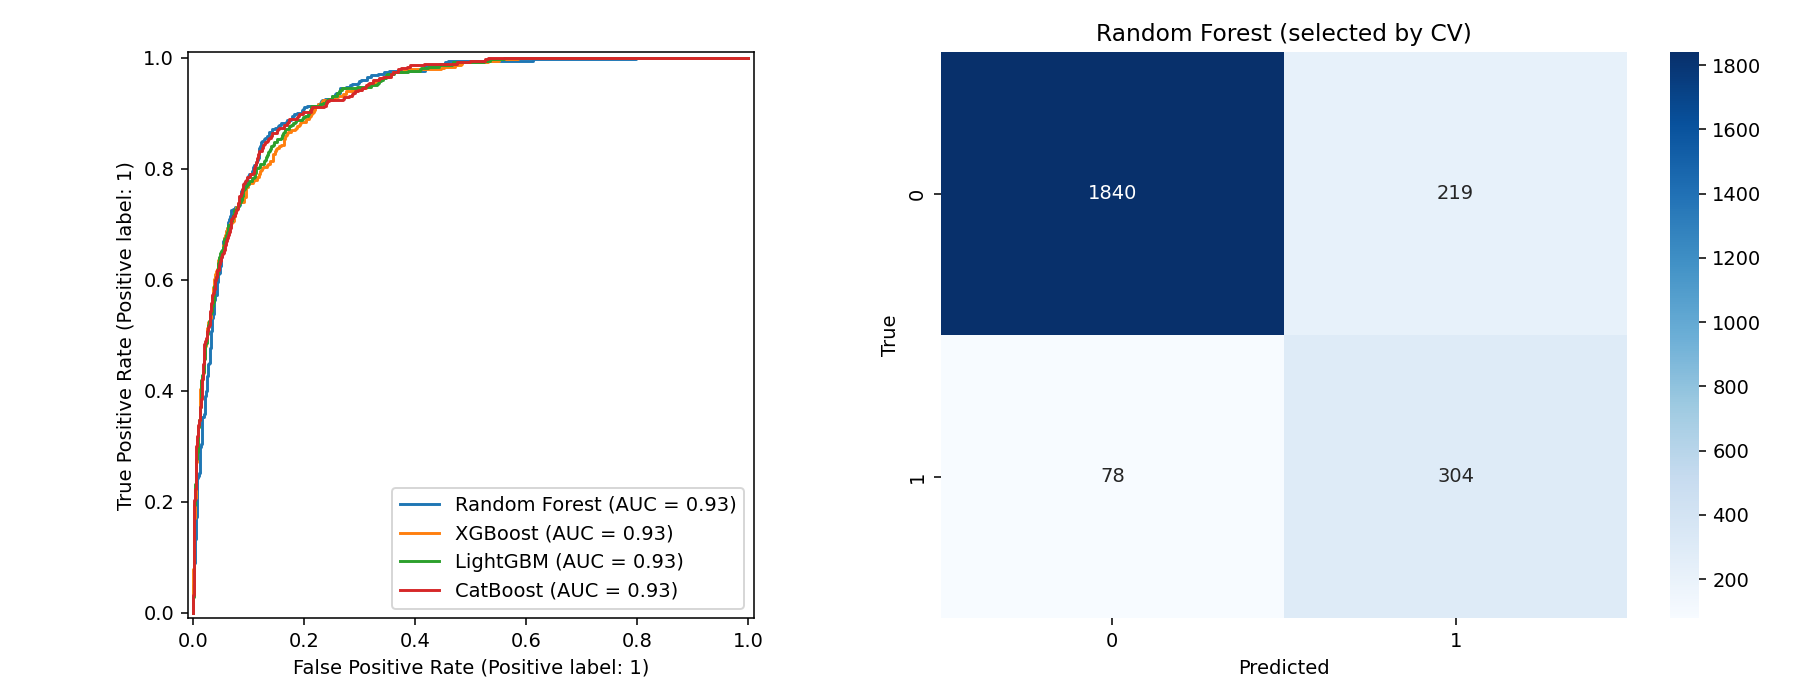

In [5]:
# Единая функция вычисляет пороговые и вероятностные метрики.
def evaluate(pipe, name):
    prob = pipe.predict_proba(X_test)[:,1]
    pred = (prob >= 0.5).astype(int)
    return dict(Model=name, Accuracy=accuracy_score(y_test,pred), Precision=precision_score(y_test,pred,zero_division=0),
        Recall=recall_score(y_test,pred), F1=f1_score(y_test,pred), ROC_AUC=roc_auc_score(y_test,prob),
        PR_AUC=average_precision_score(y_test,prob))
results = [evaluate(models[n],n) | {'CV_ROC_AUC':cv_scores[n]['mean'], 'Fit_seconds':fit_times[n]} for n in names]
results_df = pd.DataFrame(results)
display(results_df)
print('Константный baseline Accuracy:', float((y_test==0).mean()), 'ROC-AUC: 0.5; AP:', y_test.mean())
results_df.to_csv('examples/metrics_baseline.csv', index=False)

# Строим общую ROC и матрицу ошибок выбранного по CV baseline.
fig, axes = plt.subplots(1,2,figsize=(13,5))
for name, pipe in models.items():
    RocCurveDisplay.from_predictions(y_test,pipe.predict_proba(X_test)[:,1],name=name,ax=axes[0])
sns.heatmap(confusion_matrix(y_test,models[winner].predict(X_test)),annot=True,fmt='d',ax=axes[1],cmap='Blues')
axes[1].set(xlabel='Predicted',ylabel='True',title=winner+' (selected by CV)')
fig.tight_layout()
fig.savefig('examples/roc_curves.png',dpi=140)
plt.close(fig)
display(Image(filename='examples/roc_curves.png'))

Высокая Accuracy константного baseline объясняется дисбалансом. Для сравнения моделей используем ROC-AUC совместно с PR-AUC и F1; фактические значения приведены в таблице, а не взяты из примера задания.

## 8. Интерпретация и бизнес-инсайты
Важности RF и LightGBM измеряются по-разному; сравниваем порядок признаков внутри модели.
Проверяем также влияние инженерии признаков на CV (те же фолды и параметры LightGBM).
Дополнительная модель без PageValues оценивает чувствительность к доступности аналитической ценности.

По обучающей выборке доля покупок у новых посетителей выше, чем у возвращающихся;
значит утверждение «возвращающиеся всегда покупают чаще» данными не подтверждается.
В ноябре наблюдается повышенная конверсия: это гипотеза о сезонности для следующего
периода, а не доказательство эффекта конкретной акции. Важность PageValues и его
производного требует аудита доступности аналитики до покупки.


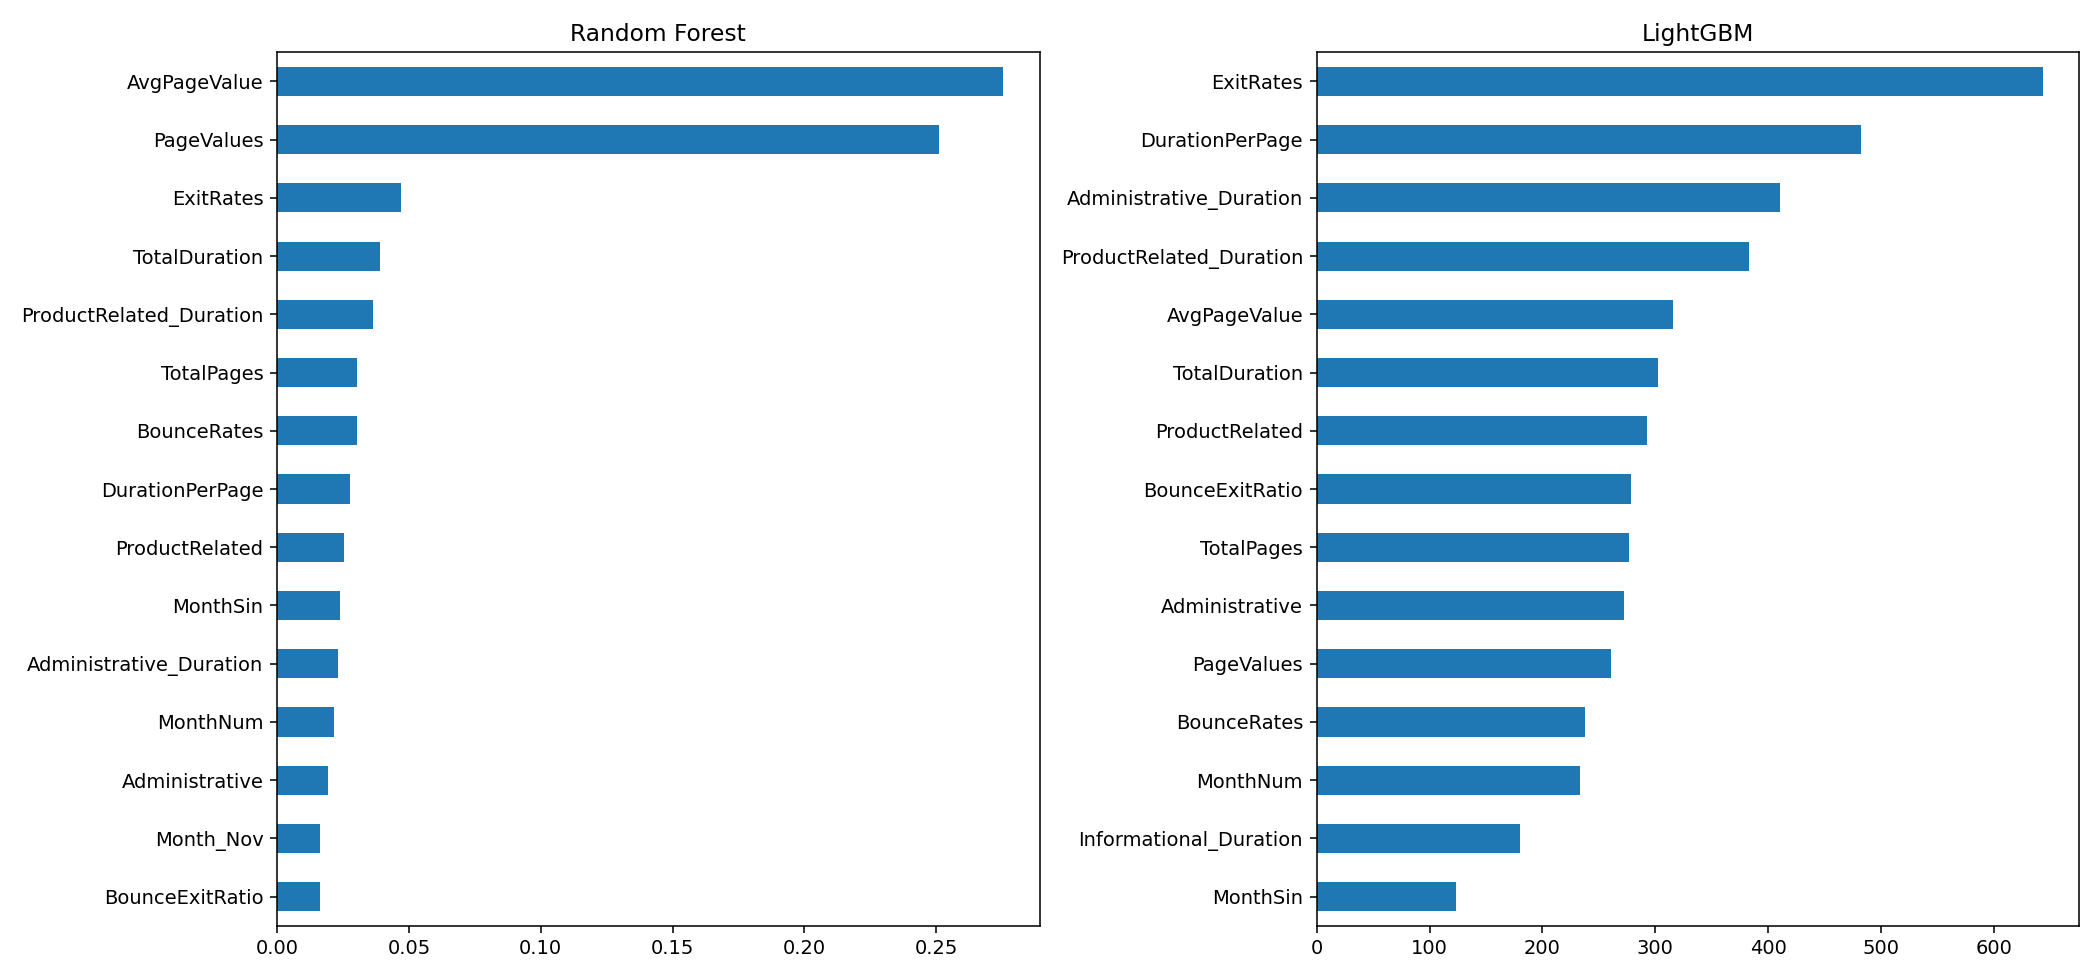

,Features,CV_ROC_AUC,CV_std
0,Original,0.927233,0.006611
1,Engineered,0.927706,0.005033
2,Without PageValues,0.775585,0.010664


,mean,count
VisitorType,,
New_Visitor,0.240919,1349
Other,0.235294,68
Returning_Visitor,0.141967,8347


,mean,count
Month,,
Aug,0.172222,360
Dec,0.131328,1363
Feb,0.020833,144
Jul,0.144476,353
June,0.102222,225
Mar,0.106000,1500
May,0.106956,2674
Nov,0.254029,2358
Oct,0.224018,433


Изменение CV ROC-AUC после инженерии: **+0.00047**. Добавление признаков не гарантирует улучшения. Различия по месяцам и типам посетителя помогают сформулировать гипотезы для A/B-теста, но не доказывают эффект рекламы. Сильное падение без PageValues означало бы зависимость качества от доступности этого поля.

In [6]:
# Сохраняем имена после One-Hot и строим важности для двух семейств.
fig, axes = plt.subplots(1,2,figsize=(15,7))
for name, ax in zip(['Random Forest','LightGBM'],axes):
    pipe = models[name]
    cols = pipe['preprocessor'].get_feature_names_out()
    imp = pd.Series(pipe['model'].feature_importances_,index=cols).sort_values(ascending=False)
    imp.to_csv('examples/'+name.lower().replace(' ','_')+'_importance.csv',header=['importance'])
    imp.head(15).sort_values().plot.barh(ax=ax,title=name)
fig.tight_layout()
fig.savefig('examples/feature_importance.png',dpi=140)
plt.close(fig)
display(Image(filename='examples/feature_importance.png'))

# Абляция оценивает изменения только по обучающей CV.
ablation = []
for label, engineered, drop in [('Original',False,False),('Engineered',True,False),('Without PageValues',True,True)]:
    pipe = make_pipeline(estimator('LightGBM'),engineered,drop)
    scores = cross_val_score(pipe,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=1)
    ablation.append(dict(Features=label,CV_ROC_AUC=float(scores.mean()),CV_std=float(scores.std())))
ablation_df = pd.DataFrame(ablation)
display(ablation_df)
ablation_df.to_csv('examples/feature_ablation.csv',index=False)
# Фактические доли помогают избежать неподтверждённых утверждений о новых посетителях.
display(eda.groupby('VisitorType')['Revenue'].agg(['mean','count']))
display(eda.groupby('Month')['Revenue'].agg(['mean','count']))
gain = ablation[1]['CV_ROC_AUC']-ablation[0]['CV_ROC_AUC']
display(Markdown(f'Изменение CV ROC-AUC после инженерии: **{gain:+.5f}**. '
    'Добавление признаков не гарантирует улучшения. Различия по месяцам и типам посетителя '
    'помогают сформулировать гипотезы для A/B-теста, но не доказывают эффект рекламы. '
    'Сильное падение без PageValues означало бы зависимость качества от доступности этого поля.'))

## 9. Тюнинг гиперпараметров (Optuna)
30 испытаний TPE, 5 стратифицированных фолдов. Подбирается семейство, выбранное по CV.
Test не используется в objective. Прирост может быть отрицательным на test; это честный результат.

In [7]:
# Пространство поиска соответствует выбранному семейству модели.
def objective(trial):
    if winner == 'Random Forest':
        params = dict(n_estimators=trial.suggest_int('n_estimators',100,400,step=50),
            max_depth=trial.suggest_int('max_depth',5,18),min_samples_leaf=trial.suggest_int('min_samples_leaf',1,12),
            max_features=trial.suggest_categorical('max_features',['sqrt',0.5,0.8]))
    elif winner == 'CatBoost':
        params = dict(iterations=trial.suggest_int('iterations',100,500,step=50),
            depth=trial.suggest_int('depth',3,8),learning_rate=trial.suggest_float('learning_rate',0.01,0.2,log=True),
            l2_leaf_reg=trial.suggest_float('l2_leaf_reg',0.1,10,log=True))
    else:
        params = dict(n_estimators=trial.suggest_int('n_estimators',100,500,step=50),
            max_depth=trial.suggest_int('max_depth',3,10), learning_rate=trial.suggest_float('learning_rate',0.01,0.2,log=True),
            subsample=trial.suggest_float('subsample',0.6,1),colsample_bytree=trial.suggest_float('colsample_bytree',0.6,1),
            reg_alpha=trial.suggest_float('reg_alpha',0.001,10,log=True),reg_lambda=trial.suggest_float('reg_lambda',0.001,10,log=True))
        if winner == 'LightGBM':
            params['num_leaves'] = trial.suggest_int('num_leaves',10,60)
            params['min_child_samples'] = trial.suggest_int('min_child_samples',10,50)
    pipe = make_pipeline(estimator(winner,params))
    return float(cross_val_score(pipe,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=1).mean())

# TPE с фиксированным seed; сохраняем журнал всех испытаний.
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective,n_trials=30)
study.trials_dataframe().to_csv('examples/optuna_trials.csv',index=False)
print('Best parameters:',study.best_params,'CV ROC-AUC:',study.best_value)
tuned = make_pipeline(estimator(winner,study.best_params))
start = time.perf_counter()
tuned.fit(X_train,y_train)
tuned_time = time.perf_counter()-start
final_name = winner+' (Optuna)'
tuned_result = evaluate(tuned,final_name) | {'CV_ROC_AUC':study.best_value,'Fit_seconds':tuned_time}
# Сохраняем baseline, если тюнинг не улучшил CV; test на решение не влияет.
use_tuned = study.best_value > cv_scores[winner]['mean']
best = tuned if use_tuned else models[winner]
best_name = final_name if use_tuned else winner
results.append(tuned_result)
display(pd.DataFrame(results))
print('Test delta ROC-AUC:',tuned_result['ROC_AUC']-next(r['ROC_AUC'] for r in results if r['Model']==winner))
print('Сохранённая модель по CV:',best_name)

Best parameters: {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 11, 'max_features': 0.5} CV ROC-AUC: 0.9345822457439009


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,CV_ROC_AUC,Fit_seconds
0,Random Forest,0.878329,0.581262,0.795812,0.671823,0.931205,0.716422,0.930773,1.021187
1,XGBoost,0.882425,0.599581,0.748691,0.665891,0.929191,0.744372,0.926500,0.765426
2,LightGBM,0.869726,0.558394,0.801047,0.658065,0.931031,0.743183,0.927706,0.405463
3,CatBoost,0.875051,0.571429,0.806283,0.668838,0.932925,0.749048,0.929600,1.539688
4,Random Forest (Optuna),0.875051,0.569620,0.824607,0.673797,0.935022,0.746833,0.934582,2.765255


Test delta ROC-AUC: 0.003816725956025002
Сохранённая модель по CV: Random Forest (Optuna)


Отчёт отделяет CV-оценку, используемую при выборе, от независимой тестовой оценки. Итоговый вариант определяется по CV; тестовый результат не служит основанием для повторного подбора.

## 10. Интерпретация через SHAP
Объясняем итоговую модель на воспроизводимой подвыборке test. Категории и числовые признаки
передаются в том виде, который получила модель. Числовые значения на SHAP-графиках масштабированы.

C:\Users\Khlulhloo\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


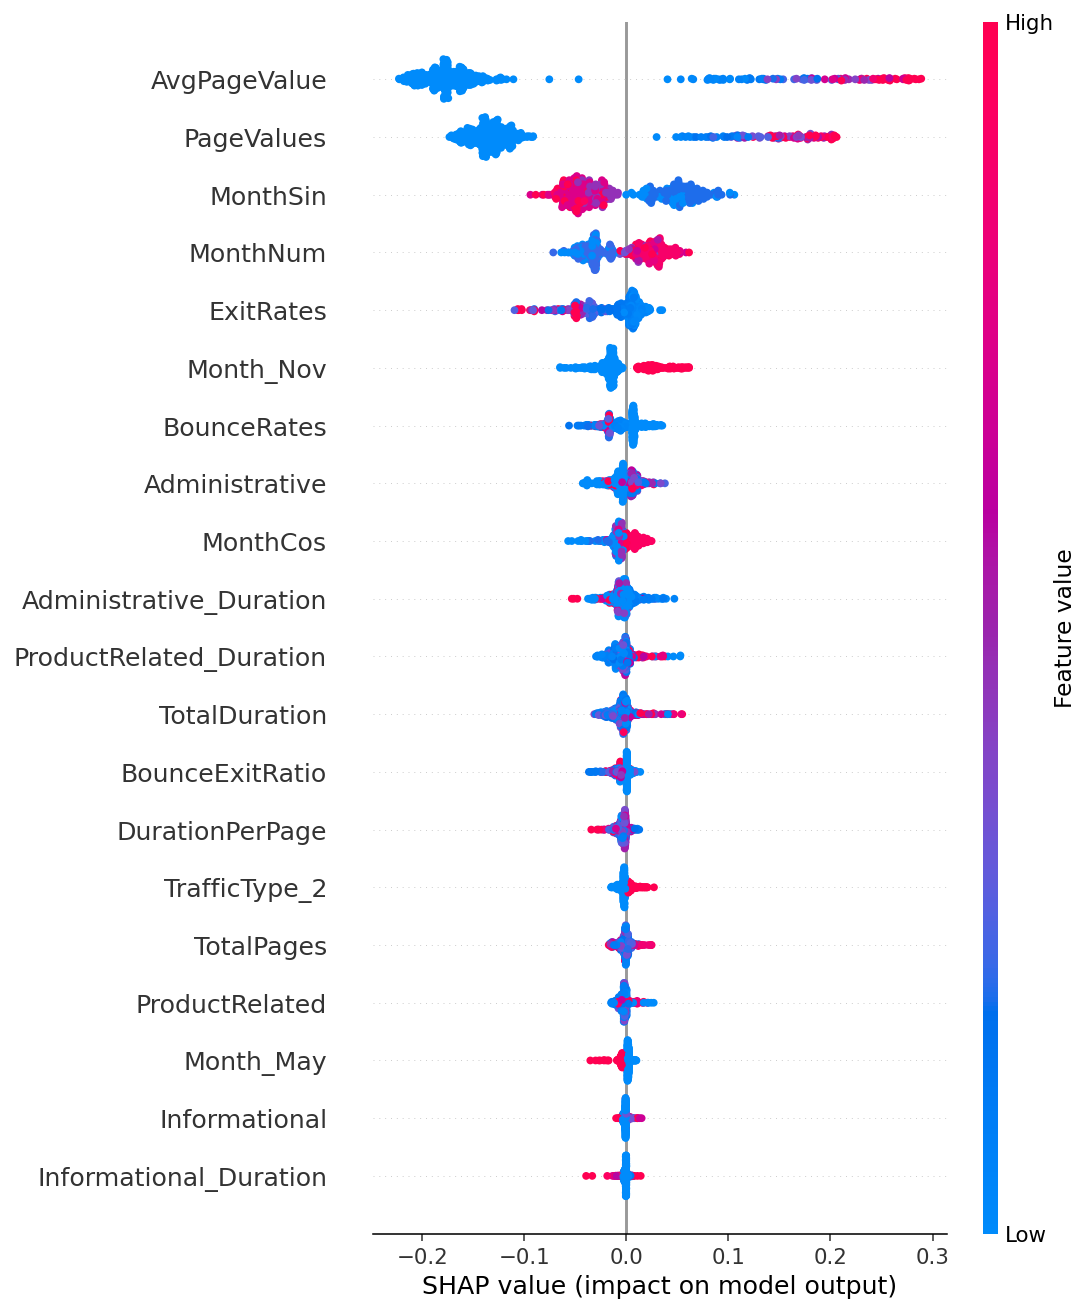

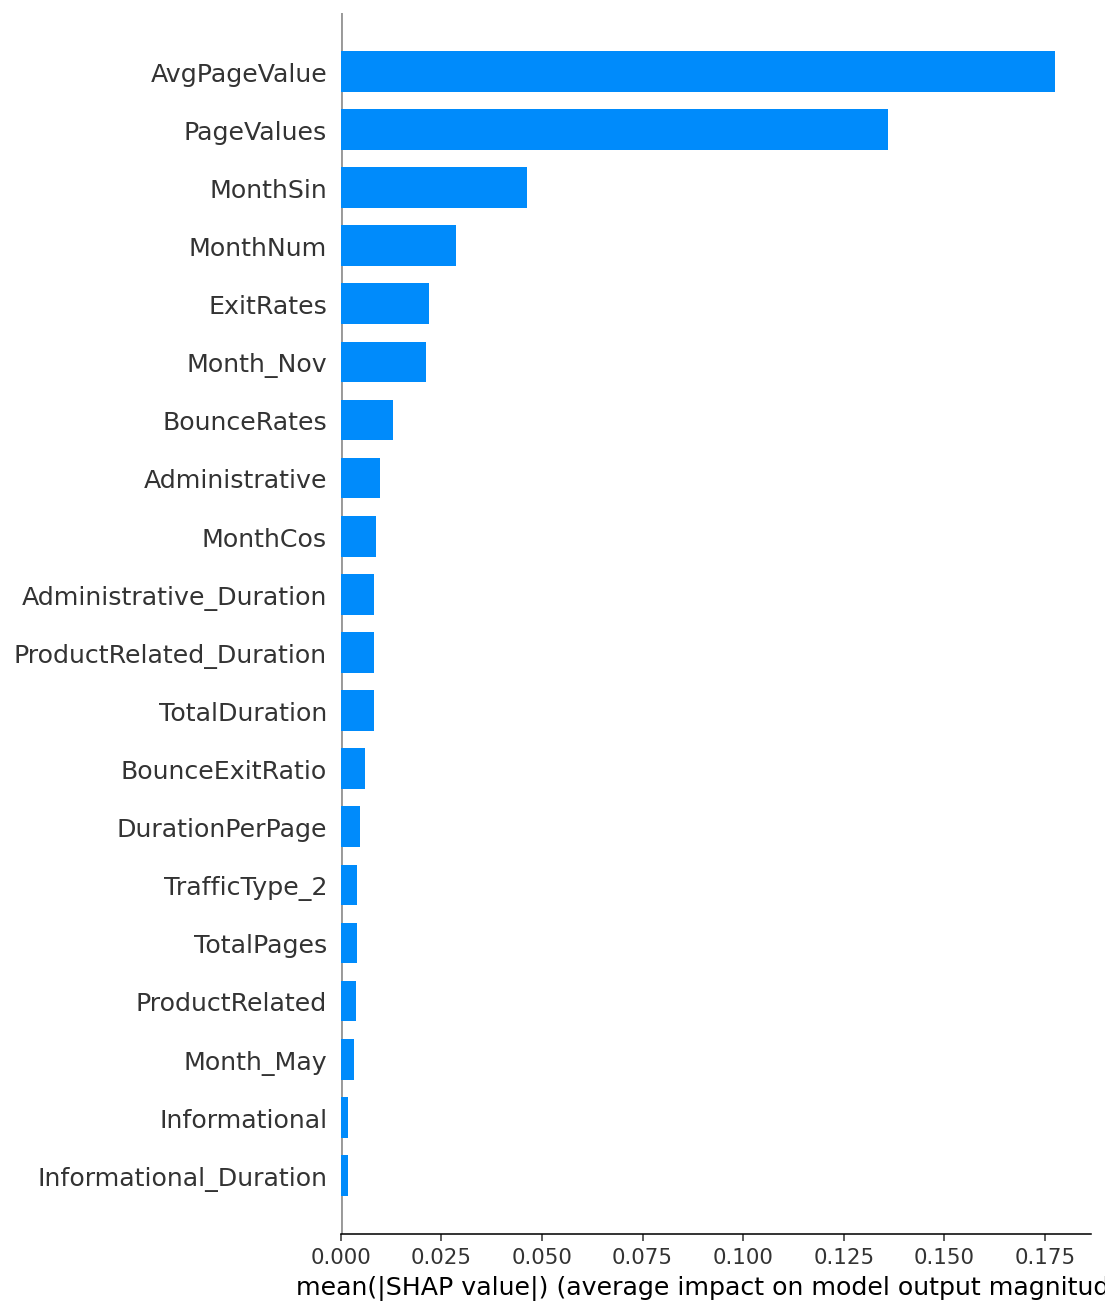

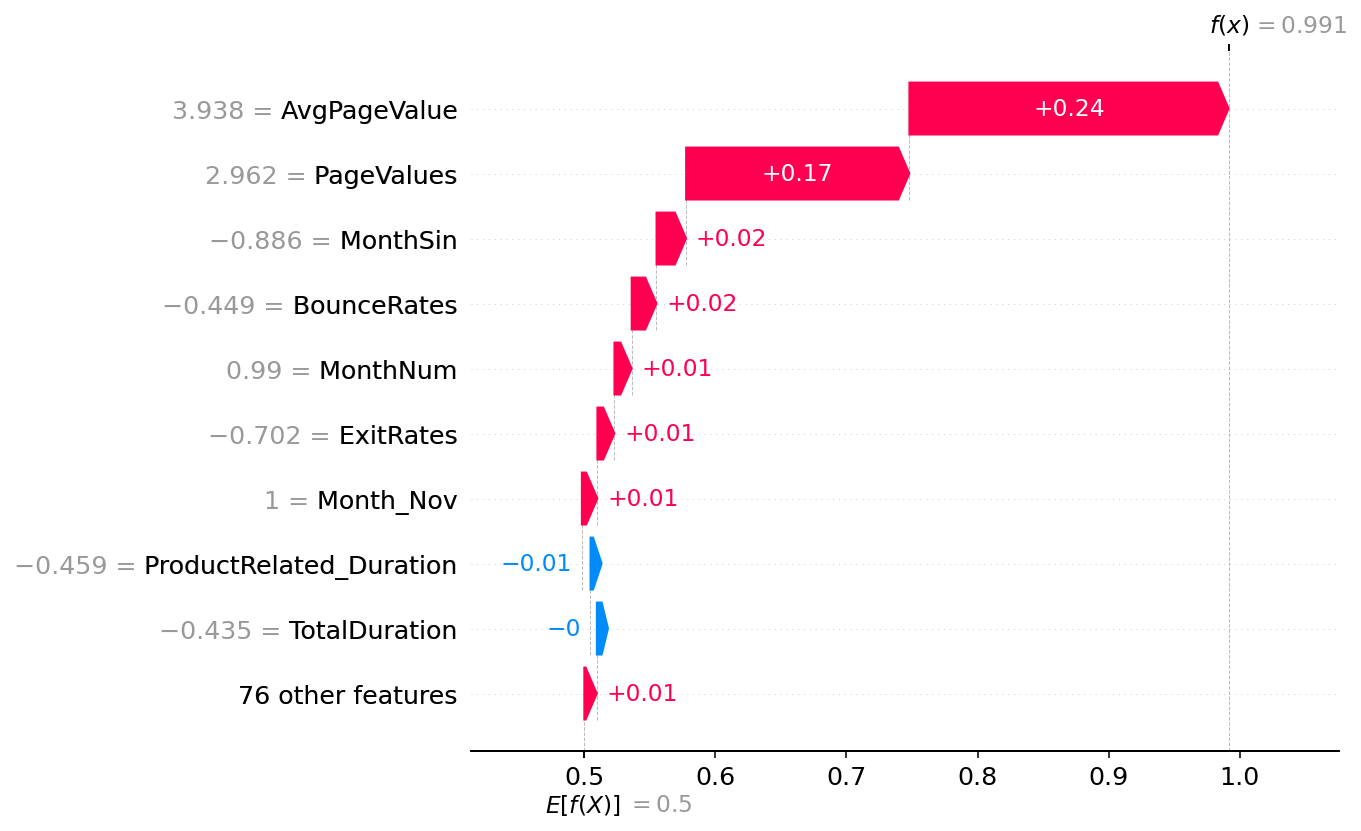

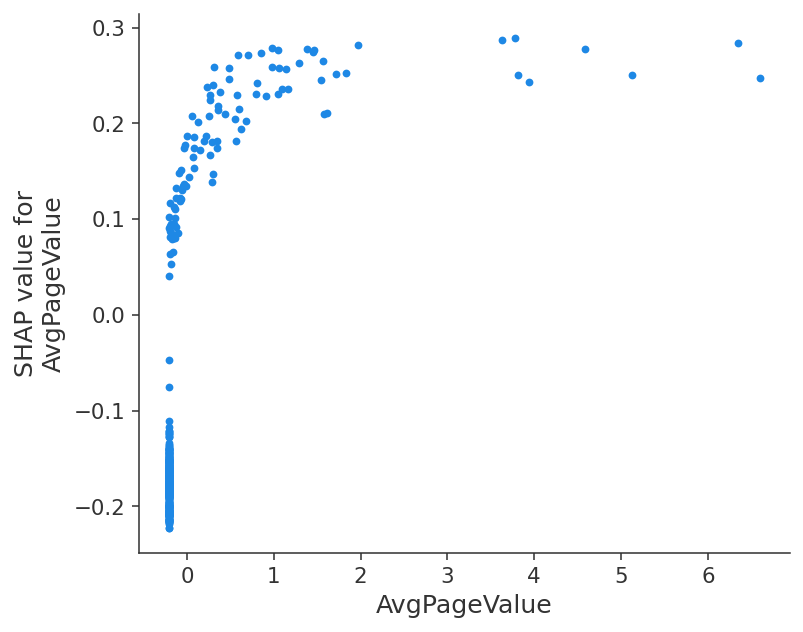

SHAP units: probability


C:\Users\Khlulhloo\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Ведущий признак по mean(|SHAP|): **AvgPageValue**. Локальные вклады (probability):

,SHAP
AvgPageValue,0.243459
PageValues,0.170290
MonthSin,0.022567
BounceRates,0.018945
MonthNum,0.013132


Вероятность выбранной сессии: 0.9914793697969696


C:\Users\Khlulhloo\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [3]:
# Преобразуем test обученными шагами Pipeline; выбираем до 500 объектов.
transformed = best['preprocessor'].transform(best['features'].transform(X_test))
feature_cols = best['preprocessor'].get_feature_names_out().tolist()
z = pd.DataFrame(transformed,columns=feature_cols,index=X_test.index)
sample = z.sample(min(500,len(z)),random_state=SEED)
explainer = shap.TreeExplainer(best['model'])
explanation = explainer(sample)
if explanation.values.ndim == 3:
    explanation = explanation[:,:,1]
values = explanation.values
np.savez_compressed('examples/shap_values.npz',values=values,base_values=explanation.base_values,index=sample.index)

# Сохраняем глобальные и локальные объяснения.
shap.summary_plot(values,sample,show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png',dpi=140,bbox_inches='tight')
plt.close('all')
shap.summary_plot(values,sample,plot_type='bar',show=False)
plt.savefig('examples/shap_bar.png',dpi=140,bbox_inches='tight')
plt.close('all')
local_idx = int(np.argmax(best['model'].predict_proba(sample)[:,1]))
shap.plots.waterfall(explanation[local_idx],show=False)
plt.savefig('examples/shap_waterfall.png',dpi=140,bbox_inches='tight')
plt.close('all')
shap_importance = pd.Series(np.abs(values).mean(axis=0),index=feature_cols).sort_values(ascending=False)
shap_importance.to_csv('examples/shap_importance.csv',header=['mean_abs_shap'])
top_feature = shap_importance.index[0]
shap.dependence_plot(top_feature,values,sample,interaction_index=None,show=False)
plt.savefig('examples/shap_dependence.png',dpi=140,bbox_inches='tight')
plt.close('all')
for file in ['shap_summary','shap_bar','shap_waterfall','shap_dependence']:
    display(Image(filename='examples/'+file+'.png'))
# Проверяем аддитивность: RF объясняет вероятность, бустинги — log-odds.
raw = values.sum(axis=1)+np.asarray(explanation.base_values)
shap_units = 'probability' if isinstance(best['model'], RandomForestClassifier) else 'log-odds'
prob_from_shap = raw if shap_units == 'probability' else 1/(1+np.exp(-raw))
print('SHAP units:', shap_units)
np.testing.assert_allclose(prob_from_shap,best['model'].predict_proba(sample)[:,1],atol=1e-5)
local = pd.Series(values[local_idx],index=feature_cols).sort_values(key=abs,ascending=False).head(5)
display(Markdown('Ведущий признак по mean(|SHAP|): **'+top_feature+'**. Локальные вклады ('+shap_units+'):'))
display(local.to_frame('SHAP'))
print('Вероятность выбранной сессии:',best['model'].predict_proba(sample.iloc[[local_idx]])[0,1])

Summary отражает распределение вкладов, waterfall — фактические причины конкретного прогноза модели. Знак вклада показывает направление изменения объясняемого выхода модели; единицы указаны в проверке выше. Для бизнес-решений нужны проверка доступности признаков, калибровка вероятностей и экспериментальная проверка гипотез.

У итогового RF лидируют AvgPageValue, PageValues, MonthSin, MonthNum и ExitRates. Это указывает на зависимость от аналитической ценности и сезонности. AvgPageValue и PageValues коррелируют, поэтому их важности нельзя трактовать как независимые эффекты.

## 11. Сохранение модели и метаданных
Каждый .pkl содержит полный Pipeline: генерацию признаков, предобработку и классификатор.
Для загрузки нужен `feature_engineering.py` рядом с кодом. scaler.pkl сохранён отдельно
по заданию; при использовании полного Pipeline повторно применять его не нужно.

In [4]:
# Сохраняем все baseline и итоговую модель с одним интерфейсом сырых данных.
files = dict(zip(names,['rf_model','xgb_model','lgbm_model','cat_model']))
for name, pipe in models.items():
    joblib.dump(pipe,'models/'+files[name]+'.pkl',compress=3)
joblib.dump(tuned,'models/tuned_model.pkl',compress=3)
joblib.dump(best,'models/best_model.pkl',compress=3)
joblib.dump(best['preprocessor'].named_transformers_['num']['scaler'],'models/scaler.pkl')
Path('models/feature_cols.json').write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding='utf-8')
Path('models/metrics.json').write_text(json.dumps({'results':results,'selected_model':best_name,
    'selection':'highest train CV ROC-AUC; test excluded','ablation':ablation},ensure_ascii=False,indent=2),encoding='utf-8')
# Версии и схема входа позволяют воспроизвести загрузку.
packages = ['pandas','numpy','scikit-learn','xgboost','lightgbm','catboost','optuna','shap',
            'matplotlib','seaborn','joblib','requests','nbformat','nbclient','ipykernel','tabulate']
versions = {p:importlib.metadata.version(p) for p in packages}
metadata = dict(author='Федорушкин Станислав',group='ПКТб-23-1',date='2026-10-29',
    seed=SEED,python=platform.python_version(),versions=versions,selected_model=best_name,
    selected_cv_roc_auc=max(study.best_value,cv_scores[winner]['mean']),best_trial_params=study.best_params,
    input_columns=X.columns.tolist(),input_dtypes=X.dtypes.astype(str).to_dict(),
    train_rows=len(X_train),test_rows=len(X_test),threshold=0.5,data=provenance)
Path('models/metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
Path('requirements.txt').write_text(''.join(p+'=='+v+'\n' for p,v in versions.items()),encoding='utf-8')
X_test.iloc[:3].to_csv('examples/inference_input.csv',index=False)
np.save('examples/inference_probabilities.npy',best.predict_proba(X_test.iloc[:3]))
loaded = joblib.load('models/best_model.pkl')
np.testing.assert_allclose(loaded.predict_proba(X_test.iloc[:3]),best.predict_proba(X_test.iloc[:3]))
print('Локальный round-trip: вероятности 3 сессий совпадают.')

Локальный round-trip: вероятности 3 сессий совпадают.


## 12. Загрузка модели из репозитория
После публикации запускается `python verify_remote.py`. Скрипт получает модель, трансформер,
список признаков и три примера через raw GitHub, затем сравнивает вероятности с сохранёнными.
В текущем локальном отчёте выполнена проверка сериализации; удалённая проверка требует,
чтобы новые файлы были опубликованы в main. Локальная проверка не выдаётся за удалённую.
Загрузка joblib допустима только из собственного доверенного репозитория.

In [5]:
# Показываем исполняемый код удалённой проверки без подмены локальным fallback.
print(Path('verify_remote.py').read_text(encoding='utf-8'))

"""Проверка опубликованных артефактов: python verify_remote.py."""
import io
import sys
import tempfile
from pathlib import Path
import importlib.util
import joblib
import numpy as np
import pandas as pd
import requests

BASE_URL = 'https://raw.githubusercontent.com/Ogn1k/ml-course-fedorushkin/main/module-4-features'
def download(path):
    # HTTP-ошибки, включая отсутствие опубликованного файла, не скрываем.
    response = requests.get(f'{BASE_URL}/{path}', timeout=90)
    response.raise_for_status()
    return response.content

def main():
    # Трансформер берём из той же доверенной ревизии, что и pipeline.
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / 'feature_engineering.py'
        path.write_bytes(download('feature_engineering.py'))
        spec = importlib.util.spec_from_file_location('feature_engineering', path)
        module = importlib.util.module_from_spec(spec)
        sys.modules['feature_engineering'] = module
        spec.loader.

## 13. Выводы
Получены четыре baseline, оптимизированный вариант, важности и объяснения SHAP.
Численные итоги выводятся из фактических результатов ниже.

Трудности: дисбаланс требует нескольких метрик; категории не имеют естественного порядка;
коррелирующие исходные и производные признаки делят важность. Нет полного времени сессии,
поэтому качество на будущих периодах нельзя оценить случайным разбиением.

Дальнейшие улучшения:
1. Проверить доступность PageValues в момент реального прогноза.
2. Собрать timestamps и провести временную валидацию.
3. Настроить порог под стоимость ошибок на отдельной validation.
4. Калибровать вероятности внутри CV.
5. Проверить Target Encoding без утечки и нативные категории CatBoost.
6. Проверить SMOTE только внутри обучающих фолдов.
7. Проверить взаимодействия и стабильность важностей на нескольких разбиениях.

In [6]:
# Генерируем итоговые выводы по реальным измерениям.
chosen = next(r for r in results if r['Model']==best_name)
display(Markdown(f"Итог: **{best_name}**, test ROC-AUC **{chosen['ROC_AUC']:.4f}**, "
    f"F1 **{chosen['F1']:.4f}**, Precision **{chosen['Precision']:.4f}**, Recall **{chosen['Recall']:.4f}**. "
    f"Изменение CV от инженерии признаков: **{gain:+.5f}**. "
    'Выбор сделан по train CV; независимый test использован для отчёта.'))

Итог: **Random Forest (Optuna)**, test ROC-AUC **0.9350**, F1 **0.6738**, Precision **0.5696**, Recall **0.8246**. Изменение CV от инженерии признаков: **+0.00047**. Выбор сделан по train CV; независимый test использован для отчёта.

## 14. Список источников и приложение
1. [Sakar, Kastro. UCI Online Shoppers (2018), DOI и CC BY 4.0](https://doi.org/10.24432/C5F88Q).
2. [Breiman. Random Forests (2001)](https://doi.org/10.1023/A:1010933404324).
3. [Chen, Guestrin. XGBoost (2016)](https://arxiv.org/abs/1603.02754).
4. [Ke et al. LightGBM (2017)](https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree).
5. [Prokhorenkova et al. CatBoost (2018)](https://arxiv.org/abs/1706.09516).
6. [Lundberg, Lee. SHAP (2017)](https://arxiv.org/abs/1705.07874).
7. [Akiba et al. Optuna (2019)](https://arxiv.org/abs/1907.10902).
8. Материалы преподавателя: «Модуль 4. Инженерия признаков» (DOCX, IPYNB, HTML)
   и практическое задание (DOCX, IPYNB). Примеры задания адаптированы:
   предобработка перенесена внутрь CV, исключён подбор по test, исправлено отображение June.

Приложение: полный код ячеек в `appendix_full_code.py`, трансформер в
`feature_engineering.py`, удалённая проверка в `verify_remote.py`.
Версии окружения перечислены ниже и в requirements.txt.

In [7]:
# Выводим версии и полный код приложения для автономного чтения отчёта.
print(Path('requirements.txt').read_text(encoding='utf-8'))
display(Markdown('```python\n'+Path('appendix_full_code.py').read_text(encoding='utf-8')+'\n```'))

pandas==2.3.3
numpy==2.3.5
scikit-learn==1.8.0
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==5.0.0
shap==0.54.1
matplotlib==3.10.7
seaborn==0.13.2
joblib==1.5.2
requests==2.34.2
nbformat==5.10.4
nbclient==0.10.2
ipykernel==7.1.0
tabulate==0.9.0



```python
# Полный код вычислительных ячеек ноутбука

# Импортируем библиотеки и фиксируем параметры воспроизводимости.
import io, json, time, hashlib, platform, importlib.metadata, zipfile
from pathlib import Path
import requests, joblib, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, RocCurveDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna, shap
SEED = 42
BASE = Path('.')
for folder in ['data', 'models', 'examples']:
    (BASE / folder).mkdir(exist_ok=True)

# Скачиваем только официальный архив; при повторном запуске используем локальный CSV.
DATA_URL = 'https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip'
csv_path = BASE / 'data/online_shoppers_intention.csv'
if not csv_path.exists():
    response = requests.get(DATA_URL, timeout=90)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        csv_path.write_bytes(archive.read('online_shoppers_intention.csv'))
df = pd.read_csv(csv_path)
assert df.shape == (12330, 18)
print(df.shape)
print(df.head().to_string())
df.info()
display(df.describe(include='all').T)
display(df['Revenue'].value_counts().to_frame('count').assign(share=df['Revenue'].value_counts(normalize=True)))
# Сохраняем контрольную сумму для проверки источника данных.
provenance = dict(url=DATA_URL, doi='10.24432/C5F88Q', license='CC BY 4.0',
                  sha256=hashlib.sha256(csv_path.read_bytes()).hexdigest())
Path('data/provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')

# Удаляем дубликаты до разделения; не используем целевую для генерации признаков.
print('Пропуски:', int(df.isna().sum().sum()), 'Дубликаты:', int(df.duplicated().sum()))
clean = df.drop_duplicates().copy()
X = clean.drop(columns='Revenue')
y = clean['Revenue'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
pd.DataFrame({'split': ['train', 'test'], 'rows': [len(y_train),len(y_test)],
              'positive_share': [y_train.mean(), y_test.mean()]}).to_csv('data/splits.csv', index=False)

# Строим шесть графиков EDA и отдельный график пропусков.
eda = X_train.assign(Revenue=y_train)
fig, axes = plt.subplots(2, 3, figsize=(18,10))
sns.countplot(data=eda, x='Revenue', ax=axes[0,0])
sns.histplot(data=eda.assign(LogDuration=np.log1p(eda['ProductRelated_Duration'])), x='LogDuration', hue='Revenue', bins=40, ax=axes[0,1])
sns.boxplot(data=eda, x='Revenue', y='PageValues', ax=axes[0,2])
sns.heatmap(eda.drop(columns=['OperatingSystems','Browser','Region','TrafficType']).select_dtypes(include='number').corr(), cmap='coolwarm', ax=axes[1,0])
eda.groupby('VisitorType')['Revenue'].mean().plot.bar(ax=axes[1,1], ylabel='Purchase share')
eda.groupby('Month')['Revenue'].mean().reindex(['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']).plot.bar(ax=axes[1,2], ylabel='Purchase share')
for ax, title in zip(axes.flat, ['Target balance','Product duration: log(1 + seconds)','Page value by target',
                              'Numeric correlations','Conversion by visitor','Conversion by month']):
    ax.set_title(title)
fig.tight_layout()
fig.savefig('examples/eda_plots.png', dpi=140)
plt.close(fig)
display(Image(filename='examples/eda_plots.png'))
fig, ax = plt.subplots(figsize=(10,3))
X_train.isna().sum().plot.bar(ax=ax, title='Missing values in training data', ylabel='Missing count')
fig.tight_layout()
fig.savefig('examples/missing_values.png', dpi=120)
plt.close(fig)
display(Image(filename='examples/missing_values.png'))

# Импортируем собственный трансформер из файла рядом с ноутбуком.
from feature_engineering import SessionFeatures
CATEGORICAL = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
def make_pipeline(model, engineered=True, drop_page_values=False):
    feature_step = SessionFeatures(engineered, drop_page_values)
    sample = feature_step.fit_transform(X_train.iloc[:2])
    numeric = [c for c in sample.columns if c not in CATEGORICAL]
    # Все обучаемые преобразования находятся внутри Pipeline, в том числе в CV.
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL)
    ], verbose_feature_names_out=False)
    return Pipeline([('features', feature_step), ('preprocessor', prep), ('model', model)])
display(SessionFeatures().fit_transform(X_train).head())
assert np.isfinite(SessionFeatures().fit_transform(X_train).select_dtypes(include='number')).all().all()

# Фиксируем CV и ограничиваем число потоков для воспроизводимого локального запуска.
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
ratio = float((y_train == 0).sum() / (y_train == 1).sum())
def estimator(name, params=None):
    p = params or {}
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=p.get('n_estimators',200), max_depth=p.get('max_depth',10),
            min_samples_leaf=p.get('min_samples_leaf',1), max_features=p.get('max_features','sqrt'),
            class_weight='balanced', random_state=SEED, n_jobs=4)
    if name == 'XGBoost':
        return XGBClassifier(**({'n_estimators':200,'max_depth':6,'learning_rate':0.1,
            'subsample':0.9,'colsample_bytree':0.9} | p), scale_pos_weight=ratio,
            random_state=SEED, eval_metric='logloss', n_jobs=4)
    if name == 'LightGBM':
        return LGBMClassifier(**({'n_estimators':200,'num_leaves':31,'max_depth':7,'learning_rate':0.05} | p),
            class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=4, subsample_freq=1)
    return CatBoostClassifier(**({'iterations':200,'depth':6,'learning_rate':0.1} | p),
        auto_class_weights='Balanced', random_seed=SEED, verbose=False, thread_count=4, allow_writing_files=False)

# Сначала оцениваем модели на обучающей CV; затем обучаем на полном train.
names = ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']
models, cv_scores, fit_times = {}, {}, {}
for name in names:
    pipe = make_pipeline(estimator(name))
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    cv_scores[name] = dict(mean=float(scores.mean()), std=float(scores.std()), folds=scores.tolist())
    start = time.perf_counter()
    models[name] = pipe.fit(X_train, y_train)
    fit_times[name] = time.perf_counter()-start
    print(name, 'CV:', cv_scores[name], 'Fit seconds:', round(fit_times[name],3), flush=True)
winner = max(names, key=lambda n: cv_scores[n]['mean'])
display(Markdown(f'Семейство для тюнинга по CV: **{winner}**. Время выше относится к финальному fit, без CV.'))

# Единая функция вычисляет пороговые и вероятностные метрики.
def evaluate(pipe, name):
    prob = pipe.predict_proba(X_test)[:,1]
    pred = (prob >= 0.5).astype(int)
    return dict(Model=name, Accuracy=accuracy_score(y_test,pred), Precision=precision_score(y_test,pred,zero_division=0),
        Recall=recall_score(y_test,pred), F1=f1_score(y_test,pred), ROC_AUC=roc_auc_score(y_test,prob),
        PR_AUC=average_precision_score(y_test,prob))
results = [evaluate(models[n],n) | {'CV_ROC_AUC':cv_scores[n]['mean'], 'Fit_seconds':fit_times[n]} for n in names]
results_df = pd.DataFrame(results)
display(results_df)
print('Константный baseline Accuracy:', float((y_test==0).mean()), 'ROC-AUC: 0.5; AP:', y_test.mean())
results_df.to_csv('examples/metrics_baseline.csv', index=False)

# Строим общую ROC и матрицу ошибок выбранного по CV baseline.
fig, axes = plt.subplots(1,2,figsize=(13,5))
for name, pipe in models.items():
    RocCurveDisplay.from_predictions(y_test,pipe.predict_proba(X_test)[:,1],name=name,ax=axes[0])
sns.heatmap(confusion_matrix(y_test,models[winner].predict(X_test)),annot=True,fmt='d',ax=axes[1],cmap='Blues')
axes[1].set(xlabel='Predicted',ylabel='True',title=winner+' (selected by CV)')
fig.tight_layout()
fig.savefig('examples/roc_curves.png',dpi=140)
plt.close(fig)
display(Image(filename='examples/roc_curves.png'))

# Сохраняем имена после One-Hot и строим важности для двух семейств.
fig, axes = plt.subplots(1,2,figsize=(15,7))
for name, ax in zip(['Random Forest','LightGBM'],axes):
    pipe = models[name]
    cols = pipe['preprocessor'].get_feature_names_out()
    imp = pd.Series(pipe['model'].feature_importances_,index=cols).sort_values(ascending=False)
    imp.to_csv('examples/'+name.lower().replace(' ','_')+'_importance.csv',header=['importance'])
    imp.head(15).sort_values().plot.barh(ax=ax,title=name)
fig.tight_layout()
fig.savefig('examples/feature_importance.png',dpi=140)
plt.close(fig)
display(Image(filename='examples/feature_importance.png'))

# Абляция оценивает изменения только по обучающей CV.
ablation = []
for label, engineered, drop in [('Original',False,False),('Engineered',True,False),('Without PageValues',True,True)]:
    pipe = make_pipeline(estimator('LightGBM'),engineered,drop)
    scores = cross_val_score(pipe,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=1)
    ablation.append(dict(Features=label,CV_ROC_AUC=float(scores.mean()),CV_std=float(scores.std())))
ablation_df = pd.DataFrame(ablation)
display(ablation_df)
ablation_df.to_csv('examples/feature_ablation.csv',index=False)
# Фактические доли помогают избежать неподтверждённых утверждений о новых посетителях.
display(eda.groupby('VisitorType')['Revenue'].agg(['mean','count']))
display(eda.groupby('Month')['Revenue'].agg(['mean','count']))
gain = ablation[1]['CV_ROC_AUC']-ablation[0]['CV_ROC_AUC']
display(Markdown(f'Изменение CV ROC-AUC после инженерии: **{gain:+.5f}**. '
    'Добавление признаков не гарантирует улучшения. Различия по месяцам и типам посетителя '
    'помогают сформулировать гипотезы для A/B-теста, но не доказывают эффект рекламы. '
    'Сильное падение без PageValues означало бы зависимость качества от доступности этого поля.'))

# Пространство поиска соответствует выбранному семейству модели.
def objective(trial):
    if winner == 'Random Forest':
        params = dict(n_estimators=trial.suggest_int('n_estimators',100,400,step=50),
            max_depth=trial.suggest_int('max_depth',5,18),min_samples_leaf=trial.suggest_int('min_samples_leaf',1,12),
            max_features=trial.suggest_categorical('max_features',['sqrt',0.5,0.8]))
    elif winner == 'CatBoost':
        params = dict(iterations=trial.suggest_int('iterations',100,500,step=50),
            depth=trial.suggest_int('depth',3,8),learning_rate=trial.suggest_float('learning_rate',0.01,0.2,log=True),
            l2_leaf_reg=trial.suggest_float('l2_leaf_reg',0.1,10,log=True))
    else:
        params = dict(n_estimators=trial.suggest_int('n_estimators',100,500,step=50),
            max_depth=trial.suggest_int('max_depth',3,10), learning_rate=trial.suggest_float('learning_rate',0.01,0.2,log=True),
            subsample=trial.suggest_float('subsample',0.6,1),colsample_bytree=trial.suggest_float('colsample_bytree',0.6,1),
            reg_alpha=trial.suggest_float('reg_alpha',0.001,10,log=True),reg_lambda=trial.suggest_float('reg_lambda',0.001,10,log=True))
        if winner == 'LightGBM':
            params['num_leaves'] = trial.suggest_int('num_leaves',10,60)
            params['min_child_samples'] = trial.suggest_int('min_child_samples',10,50)
    pipe = make_pipeline(estimator(winner,params))
    return float(cross_val_score(pipe,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=1).mean())

# TPE с фиксированным seed; сохраняем журнал всех испытаний.
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective,n_trials=30)
study.trials_dataframe().to_csv('examples/optuna_trials.csv',index=False)
print('Best parameters:',study.best_params,'CV ROC-AUC:',study.best_value)
tuned = make_pipeline(estimator(winner,study.best_params))
start = time.perf_counter()
tuned.fit(X_train,y_train)
tuned_time = time.perf_counter()-start
final_name = winner+' (Optuna)'
tuned_result = evaluate(tuned,final_name) | {'CV_ROC_AUC':study.best_value,'Fit_seconds':tuned_time}
# Сохраняем baseline, если тюнинг не улучшил CV; test на решение не влияет.
use_tuned = study.best_value > cv_scores[winner]['mean']
best = tuned if use_tuned else models[winner]
best_name = final_name if use_tuned else winner
results.append(tuned_result)
display(pd.DataFrame(results))
print('Test delta ROC-AUC:',tuned_result['ROC_AUC']-next(r['ROC_AUC'] for r in results if r['Model']==winner))
print('Сохранённая модель по CV:',best_name)

# Преобразуем test обученными шагами Pipeline; выбираем до 500 объектов.
transformed = best['preprocessor'].transform(best['features'].transform(X_test))
feature_cols = best['preprocessor'].get_feature_names_out().tolist()
z = pd.DataFrame(transformed,columns=feature_cols,index=X_test.index)
sample = z.sample(min(500,len(z)),random_state=SEED)
explainer = shap.TreeExplainer(best['model'])
explanation = explainer(sample)
if explanation.values.ndim == 3:
    explanation = explanation[:,:,1]
values = explanation.values
np.savez_compressed('examples/shap_values.npz',values=values,base_values=explanation.base_values,index=sample.index)

# Сохраняем глобальные и локальные объяснения.
shap.summary_plot(values,sample,show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png',dpi=140,bbox_inches='tight')
plt.close('all')
shap.summary_plot(values,sample,plot_type='bar',show=False)
plt.savefig('examples/shap_bar.png',dpi=140,bbox_inches='tight')
plt.close('all')
local_idx = int(np.argmax(best['model'].predict_proba(sample)[:,1]))
shap.plots.waterfall(explanation[local_idx],show=False)
plt.savefig('examples/shap_waterfall.png',dpi=140,bbox_inches='tight')
plt.close('all')
shap_importance = pd.Series(np.abs(values).mean(axis=0),index=feature_cols).sort_values(ascending=False)
shap_importance.to_csv('examples/shap_importance.csv',header=['mean_abs_shap'])
top_feature = shap_importance.index[0]
shap.dependence_plot(top_feature,values,sample,interaction_index=None,show=False)
plt.savefig('examples/shap_dependence.png',dpi=140,bbox_inches='tight')
plt.close('all')
for file in ['shap_summary','shap_bar','shap_waterfall','shap_dependence']:
    display(Image(filename='examples/'+file+'.png'))
# Проверяем аддитивность: RF объясняет вероятность, бустинги — log-odds.
raw = values.sum(axis=1)+np.asarray(explanation.base_values)
shap_units = 'probability' if isinstance(best['model'], RandomForestClassifier) else 'log-odds'
prob_from_shap = raw if shap_units == 'probability' else 1/(1+np.exp(-raw))
print('SHAP units:', shap_units)
np.testing.assert_allclose(prob_from_shap,best['model'].predict_proba(sample)[:,1],atol=1e-5)
local = pd.Series(values[local_idx],index=feature_cols).sort_values(key=abs,ascending=False).head(5)
display(Markdown('Ведущий признак по mean(|SHAP|): **'+top_feature+'**. Локальные вклады ('+shap_units+'):'))
display(local.to_frame('SHAP'))
print('Вероятность выбранной сессии:',best['model'].predict_proba(sample.iloc[[local_idx]])[0,1])

# Сохраняем все baseline и итоговую модель с одним интерфейсом сырых данных.
files = dict(zip(names,['rf_model','xgb_model','lgbm_model','cat_model']))
for name, pipe in models.items():
    joblib.dump(pipe,'models/'+files[name]+'.pkl',compress=3)
joblib.dump(tuned,'models/tuned_model.pkl',compress=3)
joblib.dump(best,'models/best_model.pkl',compress=3)
joblib.dump(best['preprocessor'].named_transformers_['num']['scaler'],'models/scaler.pkl')
Path('models/feature_cols.json').write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding='utf-8')
Path('models/metrics.json').write_text(json.dumps({'results':results,'selected_model':best_name,
    'selection':'highest train CV ROC-AUC; test excluded','ablation':ablation},ensure_ascii=False,indent=2),encoding='utf-8')
# Версии и схема входа позволяют воспроизвести загрузку.
packages = ['pandas','numpy','scikit-learn','xgboost','lightgbm','catboost','optuna','shap',
            'matplotlib','seaborn','joblib','requests','nbformat','nbclient','ipykernel','tabulate']
versions = {p:importlib.metadata.version(p) for p in packages}
metadata = dict(author='Федорушкин Станислав',group='ПКТб-23-1',date='2026-10-29',
    seed=SEED,python=platform.python_version(),versions=versions,selected_model=best_name,
    selected_cv_roc_auc=max(study.best_value,cv_scores[winner]['mean']),best_trial_params=study.best_params,
    input_columns=X.columns.tolist(),input_dtypes=X.dtypes.astype(str).to_dict(),
    train_rows=len(X_train),test_rows=len(X_test),threshold=0.5,data=provenance)
Path('models/metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
Path('requirements.txt').write_text(''.join(p+'=='+v+'\n' for p,v in versions.items()),encoding='utf-8')
X_test.iloc[:3].to_csv('examples/inference_input.csv',index=False)
np.save('examples/inference_probabilities.npy',best.predict_proba(X_test.iloc[:3]))
loaded = joblib.load('models/best_model.pkl')
np.testing.assert_allclose(loaded.predict_proba(X_test.iloc[:3]),best.predict_proba(X_test.iloc[:3]))
print('Локальный round-trip: вероятности 3 сессий совпадают.')

# Показываем исполняемый код удалённой проверки без подмены локальным fallback.
print(Path('verify_remote.py').read_text(encoding='utf-8'))

# Генерируем итоговые выводы по реальным измерениям.
chosen = next(r for r in results if r['Model']==best_name)
display(Markdown(f"Итог: **{best_name}**, test ROC-AUC **{chosen['ROC_AUC']:.4f}**, "
    f"F1 **{chosen['F1']:.4f}**, Precision **{chosen['Precision']:.4f}**, Recall **{chosen['Recall']:.4f}**. "
    f"Изменение CV от инженерии признаков: **{gain:+.5f}**. "
    'Выбор сделан по train CV; независимый test использован для отчёта.'))

# Выводим версии и полный код приложения для автономного чтения отчёта.
print(Path('requirements.txt').read_text(encoding='utf-8'))
display(Markdown('```python\n'+Path('appendix_full_code.py').read_text(encoding='utf-8')+'\n```'))
```